Original Dataset:
        Product      Brand Product Code  \
0  Mobile Phone   Motorola     88EB4558   
1        Laptop       Oppo     416DFEEB   
2  Mobile Phone    Samsung     9F975B08   
3        Laptop       Sony     73D2A7CC   
4        Laptop  Microsoft     CCE0B80D   

                               Product Specification   Price Inward Date  \
0  Site candidate activity company there bit insi...   78570  2023-08-02   
1            Beat put care fight affect address his.   44613  2023-10-03   
2           Energy special low seven place audience.  159826  2025-03-19   
3  Friend record hard contain minute we role sea ...   20911  2024-02-06   
4   Program recently feeling save tree hotel people.   69832  2023-08-10   

  Dispatch Date  Quantity Sold  Customer Name Customer Location   Region  \
0    2023-08-03              6   William Hess      South Kelsey  Central   
1    2023-10-06              1    Larry Smith        North Lisa    South   
2    2025-03-20              5  Leah C

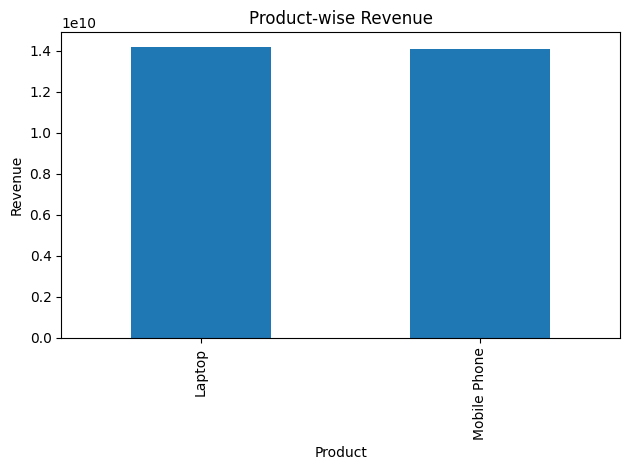

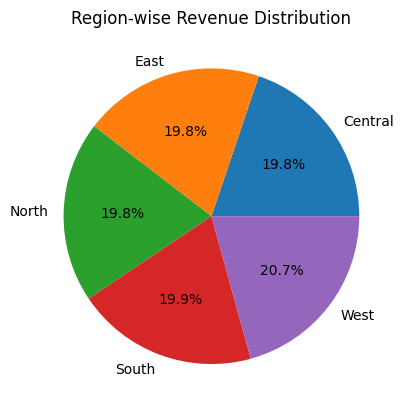

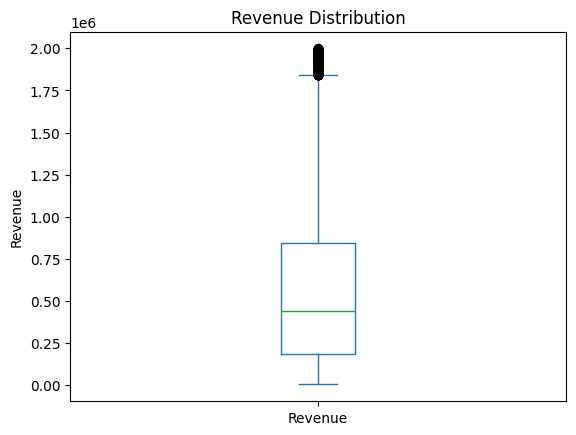


Cleaned dataset saved successfully!


In [1]:

# Experiment 1: Data Loading, Storage and File Formats
# Problem Statement: Analyzing Sales Data from Multiple File Formats

# 1. Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2. Load the original dataset
df_original = pd.read_csv('mobile_sales_data.csv')

print("Original Dataset:")
print(df_original.head())

print("\nDataset Shape:")
print(df_original.shape)

# 3. Store data in different file formats

# Divide original dataset into three non-overlapping parts
csv_part = df_original.iloc[:16667]
excel_part = df_original.iloc[16667:33334]
json_part = df_original.iloc[33334:]

# Save data in different formats
csv_part.to_csv('sales.csv', index=False)

excel_part.to_excel('sales.xlsx', index=False)

json_part.to_json(
    'sales.json',
    orient='records',
    indent=4
)

print("\nFiles created successfully!")

# 4. Load data from CSV, Excel and JSON

df_csv = pd.read_csv('sales.csv')
df_excel = pd.read_excel('sales.xlsx')
df_json = pd.read_json('sales.json')

print("\nCSV Data:")
print(df_csv.head())

print("\nExcel Data:")
print(df_excel.head())

print("\nJSON Data:")
print(df_json.head())

# 5. Explore the datasets

print("\nCSV Dataset Information:")
df_csv.info()

print("\nStatistical Summary:")
print(df_csv.describe())

print("\nMissing Values:")
print(df_original.isnull().sum())

print("\nDuplicate Records:")
print(df_original.duplicated().sum())

print("\nUnique Values:")
print(df_original.nunique())

# 6. Combine all datasets

df = pd.concat(
    [df_csv, df_excel, df_json],
    ignore_index=True
)

print("\nCombined Dataset:")
print(df.head())

print("\nCombined Shape:")
print(df.shape)

# 7. Data Cleaning

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Handle missing values
# These fields are not applicable to mobile phones
df['Core Specification'] = df['Core Specification'].fillna(
    'Not Applicable'
)

df['SSD'] = df['SSD'].fillna('Not Applicable')

# Convert date columns into datetime format
df['Inward Date'] = pd.to_datetime(
    df['Inward Date'], errors='coerce'
)

df['Dispatch Date'] = pd.to_datetime(
    df['Dispatch Date'], errors='coerce'
)

# Convert numerical columns
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')
df['Quantity Sold'] = pd.to_numeric(
    df['Quantity Sold'], errors='coerce'
)

# Check missing values after cleaning
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

# 8. Data Transformation

# Calculate revenue
df['Revenue'] = df['Price'] * df['Quantity Sold']

# Calculate dispatch duration in days
df['Dispatch_Days'] = (
    df['Dispatch Date'] - df['Inward Date']
).dt.days

# Extract month from dispatch date
df['Month'] = df['Dispatch Date'].dt.month_name()

# Create a price category
df['Price_Category'] = pd.cut(
    df['Price'],
    bins=[0, 25000, 50000, 100000, float('inf')],
    labels=['Low', 'Medium', 'High', 'Premium']
)

print("\nTransformed Dataset:")
print(df.head())

# 9. Data Analysis

# Total Revenue
print("\nTotal Revenue:")
print(df['Revenue'].sum())

# Average Revenue per Record
print("\nAverage Revenue per Record:")
print(df['Revenue'].mean())

# Total Quantity Sold
print("\nTotal Quantity Sold:")
print(df['Quantity Sold'].sum())

# Product-wise Revenue
print("\nProduct-wise Revenue:")
print(df.groupby('Product')['Revenue'].sum())

# Brand-wise Revenue
print("\nBrand-wise Revenue:")
print(df.groupby('Brand')['Revenue'].sum())

# Region-wise Revenue
print("\nRegion-wise Revenue:")
print(df.groupby('Region')['Revenue'].sum())

# Monthly Revenue
print("\nMonthly Revenue:")
print(df.groupby('Month', observed=True)['Revenue'].sum())

# Product-wise Quantity Sold
print("\nProduct-wise Quantity:")
print(df.groupby('Product')['Quantity Sold'].sum())

# 10. Data Visualization

# Bar Plot - Product-wise Revenue
df.groupby('Product')['Revenue'].sum().plot(
    kind='bar',
    title='Product-wise Revenue'
)

plt.xlabel('Product')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()

# Pie Chart - Region-wise Revenue
df.groupby('Region')['Revenue'].sum().plot(
    kind='pie',
    autopct='%1.1f%%',
    title='Region-wise Revenue Distribution'
)

plt.ylabel('')
plt.show()

# Box Plot - Revenue Distribution
df['Revenue'].plot(
    kind='box',
    title='Revenue Distribution'
)

plt.ylabel('Revenue')
plt.show()

# 11. Save the final cleaned dataset

df.to_csv('cleaned_mobile_sales.csv', index=False)

print("\nCleaned dataset saved successfully!")
